# Transformer Attention Visualization
This notebook demonstrates how to extract and visualize attention weights from a pretrained BERT model using HuggingFace.

In [2]:
from transformers import BertTokenizer, BertModel
import torch

tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
model = BertModel.from_pretrained('bert-base-uncased', output_attentions=True)

text = "I grew up in France, now I live in Boston, I speak fluent French."
inputs = tokenizer(text, return_tensors='pt')
outputs = model(**inputs)
attentions = outputs.attentions
attentions[-1].shape

torch.Size([1, 12, 19, 19])

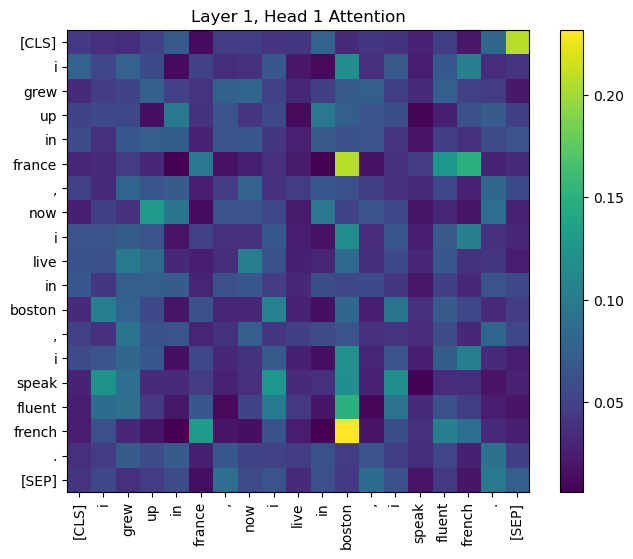

In [3]:
import matplotlib.pyplot as plt

layer = 0
head = 0

attn = attentions[layer][0, head].detach().numpy()
tokens = tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])

plt.figure(figsize=(8,6))
plt.imshow(attn)
plt.colorbar()
plt.xticks(range(len(tokens)), tokens, rotation=90)
plt.yticks(range(len(tokens)), tokens)
plt.title(f'Layer {layer+1}, Head {head+1} Attention')
plt.show()

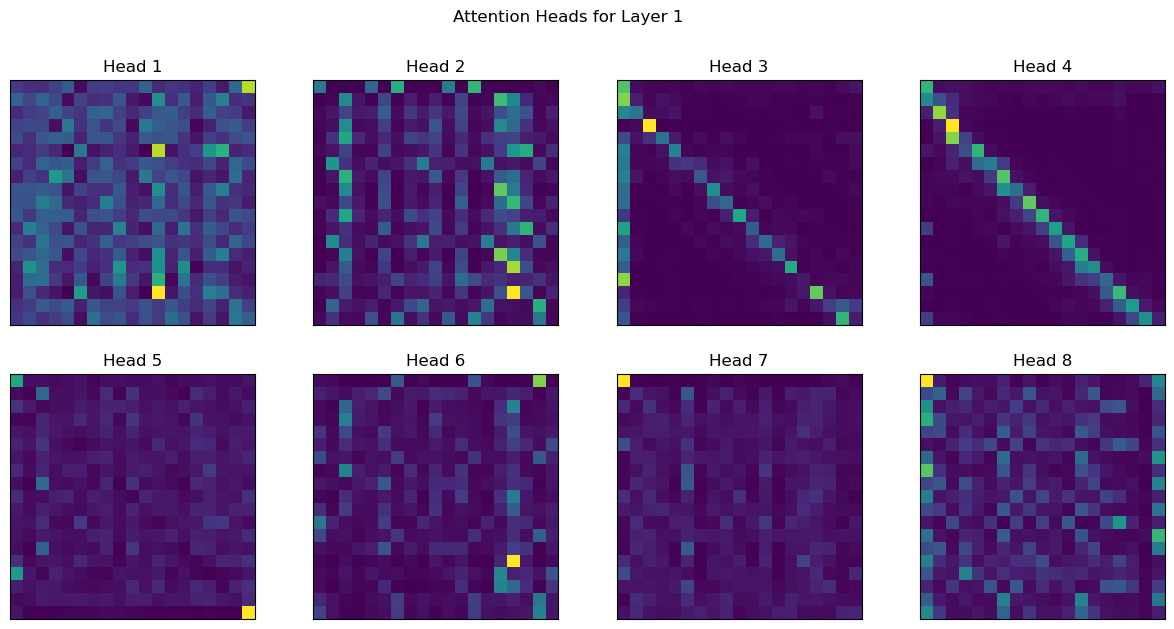

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(15,7))
heads = attentions[layer][0].detach().numpy()

for i, ax in enumerate(axes.flatten()):
    ax.imshow(heads[i])
    ax.set_title(f'Head {i+1}')
    ax.set_xticks([])
    ax.set_yticks([])

plt.suptitle(f'Attention Heads for Layer {layer+1}')
plt.show()